# Tugas Praktikum 6: Clustering (Advance)
**Mata Kuliah:** Data Mining | **Nama:** Muhammad Fardan Hafidz | **NRP:** 5054251021  
**Topik:** Penerapan dan Evaluasi Komparatif Agglomerative, DBSCAN, GMM, dan Spectral Clustering pada Dataset Palmer Penguins

## 1. Unduh dan Import Dataset

Dataset yang digunakan adalah **Palmer Penguins** (Horst, Hill, dan Gorman, 2020) yang mencatat morfologi fisik tiga spesies penguin (*Adelie*, *Chinstrap*, *Gentoo*):
- `bill_length_mm`: Panjang paruh (mm)
- `bill_depth_mm`: Kedalaman paruh (mm)
- `flipper_length_mm`: Panjang sirip (mm)
- `body_mass_g`: Massa tubuh (gram)

Kolom `species` disimpan sebagai label acuan ground truth untuk **evaluasi eksternal** dan tidak disertakan dalam pembentukan kluster.

In [1]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, rand_score, adjusted_rand_score, normalized_mutual_info_score
from scipy.cluster.hierarchy import dendrogram, linkage

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_columns', None)

In [2]:
url = "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv"
try:
    df_raw = pd.read_csv(url)
except Exception:
    local_path = "penguins.csv" if os.path.exists("penguins.csv") else os.path.join("tugas-clustering-advance", "penguins.csv")
    df_raw = pd.read_csv(local_path)

display(df_raw.head())

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [3]:
print(f"Dimensi dataset awal: {df_raw.shape[0]} baris, {df_raw.shape[1]} kolom\n")
df_raw.info()

Dimensi dataset awal: 344 baris, 8 kolom

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 21.6+ KB


## 2. Eksplorasi dan Pembersihan Data

In [4]:
missing_vals = df_raw.isna().sum()
print("Jumlah Nilai Kosong per Kolom:")
print(missing_vals)

Jumlah Nilai Kosong per Kolom:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64


In [5]:
features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
target = 'species'

# Hapus baris dengan nilai kosong pada fitur numerik atau kolom species
df = df_raw.dropna(subset=features + [target]).copy().reset_index(drop=True)

print(f"Baris sebelum pembersihan : {len(df_raw)}")
print(f"Baris sesudah pembersihan : {len(df)}")
print(f"Jumlah baris tereliminasi : {len(df_raw) - len(df)}\n")
print("Distribusi Ground Truth per Spesies:")
print(df[target].value_counts())

Baris sebelum pembersihan : 344
Baris sesudah pembersihan : 342
Jumlah baris tereliminasi : 2

Distribusi Ground Truth per Spesies:
species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64


In [6]:
# Statistik deskriptif fitur numerik
display(df[features].describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']])

,mean,std,min,25%,50%,75%,max
bill_length_mm,43.921930,5.459584,32.1,39.225,44.45,48.5,59.6
bill_depth_mm,17.151170,1.974793,13.1,15.600,17.30,18.7,21.5
flipper_length_mm,200.915205,14.061714,172.0,190.000,197.00,213.0,231.0
body_mass_g,4201.754386,801.954536,2700.0,3550.000,4050.00,4750.0,6300.0


**Observasi Skala:** Fitur `body_mass_g` memiliki varians ribuan gram (std ≈ 802), sedangkan paruh dan sirip hanya berorde milimeter (std 1.97–14.06). Tanpa penyeragaman skala, perhitungan jarak Euclidean akan sepenuhnya didominasi oleh massa tubuh. Standardisasi Z-score mutlak diterapkan.

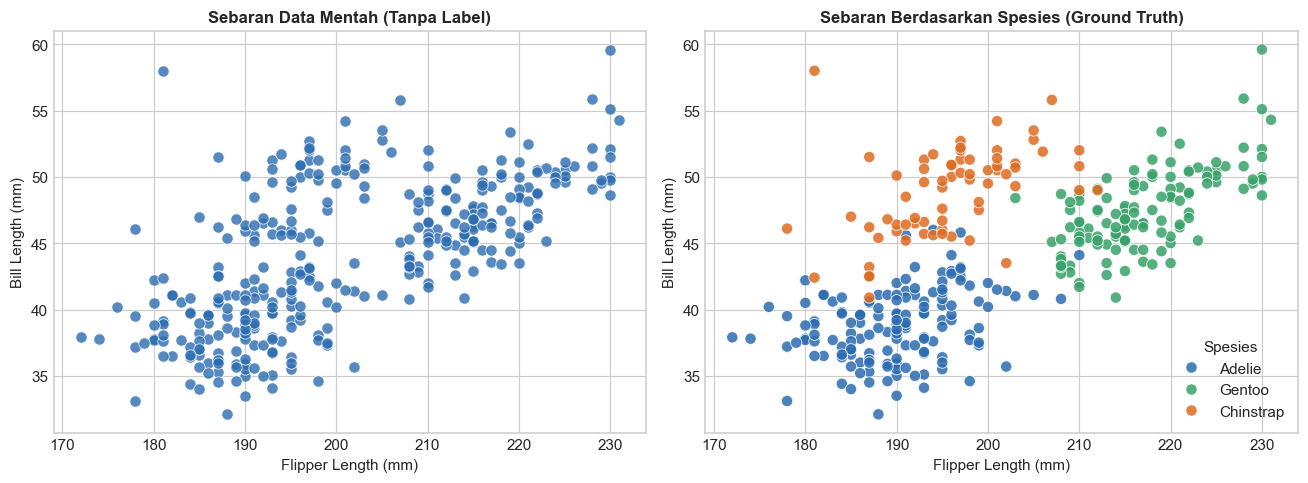

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.scatterplot(data=df, x='flipper_length_mm', y='bill_length_mm', color='#2B6CB0', alpha=0.8, s=55, ax=axes[0])
axes[0].set_title("Sebaran Data Mentah (Tanpa Label)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Flipper Length (mm)")
axes[0].set_ylabel("Bill Length (mm)")

palette_gt = {'Adelie': '#2B6CB0', 'Chinstrap': '#DD6B20', 'Gentoo': '#38A169'}
sns.scatterplot(data=df, x='flipper_length_mm', y='bill_length_mm', hue=target, palette=palette_gt, alpha=0.85, s=55, ax=axes[1])
axes[1].set_title("Sebaran Berdasarkan Spesies (Ground Truth)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Flipper Length (mm)")
axes[1].set_ylabel("Bill Length (mm)")
axes[1].legend(title='Spesies', loc='lower right')

plt.tight_layout()
plt.show()

## 3. Standardisasi Data
Transformasi Z-score: $z = \frac{x - \mu}{\sigma}$ menstandarkan seluruh fitur agar memiliki $\mu = 0$ dan $\sigma^2 = 1$.

In [8]:
X = df[features].values
y = df[target].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

display(pd.DataFrame(X_scaled, columns=features).describe().round(3).T[['mean', 'std', 'min', 'max']])

,mean,std,min,max
bill_length_mm,0.0,1.001,-2.169,2.876
bill_depth_mm,0.0,1.001,-2.054,2.205
flipper_length_mm,-0.0,1.001,-2.059,2.143
body_mass_g,0.0,1.001,-1.875,2.620


## 4. Penerapan Empat Algoritma Clustering Lanjutan

Distribusi kluster Agglomerative:
0    162
1    123
2     57
Name: count, dtype: int64


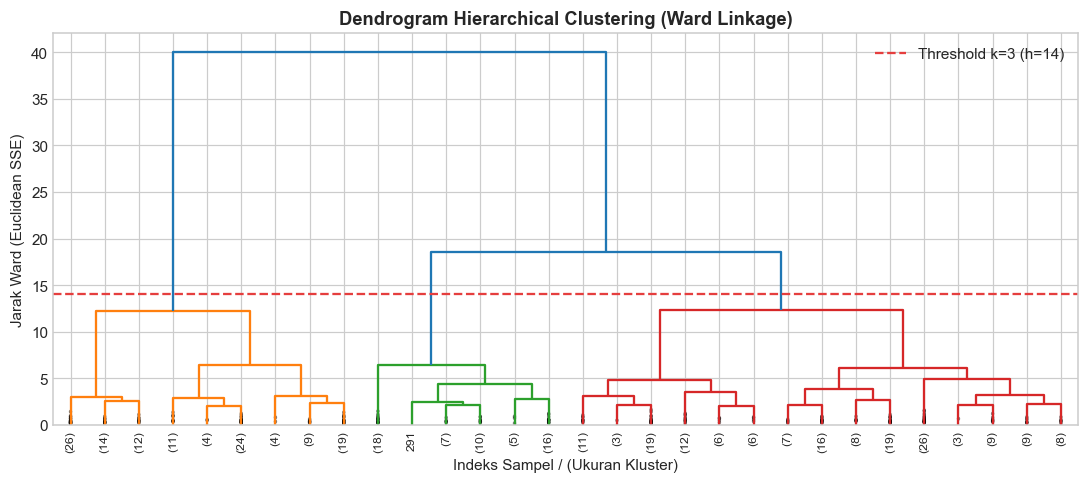

In [9]:
# 4.1 Agglomerative Clustering (k=3, Ward Linkage)
Z = linkage(X_scaled, method='ward')

plt.figure(figsize=(10, 4.5))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90., leaf_font_size=8., show_contracted=True, color_threshold=14)
plt.axhline(y=14, color='#E53E3E', linestyle='--', linewidth=1.5, label='Threshold k=3 (h=14)')
plt.title("Dendrogram Hierarchical Clustering (Ward Linkage)", fontsize=12, fontweight='bold')
plt.xlabel("Indeks Sampel / (Ukuran Kluster)")
plt.ylabel("Jarak Ward (Euclidean SSE)")
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

agg = AgglomerativeClustering(n_clusters=3, linkage='ward')
labels_agg = agg.fit_predict(X_scaled)

print("Distribusi kluster Agglomerative:")
print(pd.Series(labels_agg).value_counts().sort_index())

In [10]:
# 4.2 DBSCAN Parameter Sweep (MinPts = 5)
eps_values = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
dbscan_records = []

for eps in eps_values:
    db = DBSCAN(eps=eps, min_samples=5).fit(X_scaled)
    lbls = db.labels_
    n_cl = len(set(lbls) - {-1})
    n_ns = (lbls == -1).sum()
    mask = lbls != -1
    sil = silhouette_score(X_scaled[mask], lbls[mask]) if n_cl >= 2 and mask.sum() > n_cl else np.nan
    dbscan_records.append({
        'eps': eps,
        'MinPts': 5,
        'n_clusters': n_cl,
        'n_noise': n_ns,
        'noise_pct': round((n_ns / len(lbls)) * 100, 2),
        'silhouette_valid': round(sil, 4) if not np.isnan(sil) else None
    })

df_db_sweep = pd.DataFrame(dbscan_records)
display(df_db_sweep)

# Model DBSCAN evaluasi utama: eps=0.8 (noise minimal 1.5%, 2 kluster utama)
# Catatan: eps=0.5 menghasilkan 4 kluster dengan 69 titik noise (20.2%)
db_opt = DBSCAN(eps=0.8, min_samples=5).fit(X_scaled)
labels_db = db_opt.labels_

,eps,MinPts,n_clusters,n_noise,noise_pct,silhouette_valid
0,0.3,5,4,317,92.69,0.5767
1,0.4,5,10,171,50.00,0.3822
2,0.5,5,4,69,20.18,0.4235
3,0.6,5,2,33,9.65,0.5572
4,0.7,5,2,16,4.68,0.5509
5,0.8,5,2,5,1.46,0.5357
6,0.9,5,2,2,0.58,0.5344
7,1.0,5,2,1,0.29,0.5336


In [11]:
# 4.3 Gaussian Mixture Models (GMM, k=3)
gmm = GaussianMixture(n_components=3, covariance_type='full', random_state=42)
labels_gmm = gmm.fit_predict(X_scaled)

print(f"Konvergensi EM GMM: iterasi={gmm.n_iter_}")
print("Distribusi kluster GMM:")
print(pd.Series(labels_gmm).value_counts().sort_index())

Konvergensi EM GMM: iterasi=14
Distribusi kluster GMM:
0     67
1    123
2    152
Name: count, dtype: int64


In [12]:
# 4.4 Spectral Clustering (k=3)
spectral = SpectralClustering(
    n_clusters=3,
    affinity='nearest_neighbors',
    n_neighbors=15,
    random_state=42,
    assign_labels='kmeans'
)
labels_spectral = spectral.fit_predict(X_scaled)

print("Distribusi kluster Spectral Clustering:")
print(pd.Series(labels_spectral).value_counts().sort_index())

Distribusi kluster Spectral Clustering:
0    159
1    123
2     60
Name: count, dtype: int64


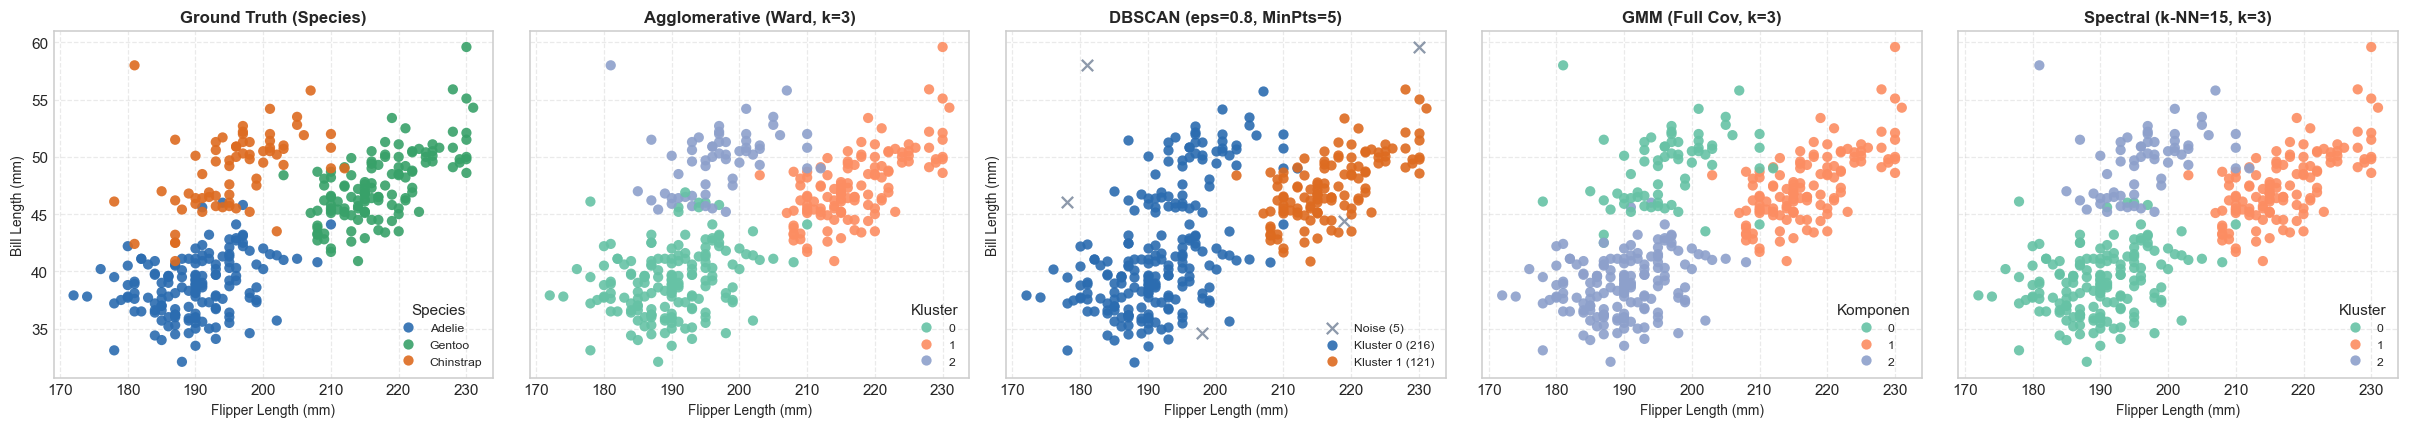

In [13]:
# 4.5 Visualisasi Komparasi Hasil Keempat Algoritma terhadap Ground Truth
fig, axes = plt.subplots(1, 5, figsize=(22, 4), sharex=True, sharey=True)

x_c, y_c = 'flipper_length_mm', 'bill_length_mm'

# 1. Ground Truth
sns.scatterplot(data=df, x=x_c, y=y_c, hue=target, palette=palette_gt, s=45, alpha=0.9, ax=axes[0], edgecolor='none')
axes[0].set_title("Ground Truth (Species)", fontsize=11, fontweight='bold')
axes[0].legend(title='Species', loc='lower right', fontsize=8)

# 2. Agglomerative
sns.scatterplot(data=df, x=x_c, y=y_c, hue=labels_agg, palette='Set2', s=45, alpha=0.9, ax=axes[1], edgecolor='none')
axes[1].set_title("Agglomerative (Ward, k=3)", fontsize=11, fontweight='bold')
axes[1].legend(title='Kluster', loc='lower right', fontsize=8)

# 3. DBSCAN (eps=0.8, MinPts=5)
db_palette = {-1: '#718096', 0: '#2B6CB0', 1: '#DD6B20'}
for cl in sorted(set(labels_db)):
    m = (labels_db == cl)
    lbl_text = f"Noise ({m.sum()})" if cl == -1 else f"Kluster {cl} ({m.sum()})"
    axes[2].scatter(df.loc[m, x_c], df.loc[m, y_c],
                    c=db_palette.get(cl, '#805AD5'),
                    marker='x' if cl == -1 else 'o',
                    s=55 if cl == -1 else 45,
                    alpha=0.9 if cl != -1 else 0.8,
                    label=lbl_text, linewidths=1.5 if cl == -1 else 0)
axes[2].set_title("DBSCAN (eps=0.8, MinPts=5)", fontsize=11, fontweight='bold')
axes[2].legend(loc='lower right', fontsize=8)

# 4. GMM
sns.scatterplot(data=df, x=x_c, y=y_c, hue=labels_gmm, palette='Set2', s=45, alpha=0.9, ax=axes[3], edgecolor='none')
axes[3].set_title("GMM (Full Cov, k=3)", fontsize=11, fontweight='bold')
axes[3].legend(title='Komponen', loc='lower right', fontsize=8)

# 5. Spectral
sns.scatterplot(data=df, x=x_c, y=y_c, hue=labels_spectral, palette='Set2', s=45, alpha=0.9, ax=axes[4], edgecolor='none')
axes[4].set_title("Spectral (k-NN=15, k=3)", fontsize=11, fontweight='bold')
axes[4].legend(title='Kluster', loc='lower right', fontsize=8)

for ax in axes:
    ax.set_xlabel("Flipper Length (mm)", fontsize=9)
    ax.set_ylabel("Bill Length (mm)", fontsize=9)
    ax.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

## 5. Evaluasi Hasil Clustering & Uji Kestabilan

In [14]:
# 1. Silhouette Score (Evaluasi Internal)
# Khusus DBSCAN dihitung tanpa noise (5 titik dieliminasi)
mask_db = (labels_db != -1)
noise_dropped = (~mask_db).sum()

sil_agg = silhouette_score(X_scaled, labels_agg)
sil_db = silhouette_score(X_scaled[mask_db], labels_db[mask_db])
sil_gmm = silhouette_score(X_scaled, labels_gmm)
sil_spec = silhouette_score(X_scaled, labels_spectral)

# 2. Rand Index, ARI, dan NMI (Evaluasi Eksternal terhadap Ground Truth)
algo_dict = {
    'Agglomerative': labels_agg,
    'DBSCAN (eps=0.8)': labels_db,
    'GMM': labels_gmm,
    'Spectral': labels_spectral
}

ext_metrics = {}
for name, lbls in algo_dict.items():
    ext_metrics[name] = {
        'Rand Index': rand_score(y, lbls),
        'ARI': adjusted_rand_score(y, lbls),
        'NMI': normalized_mutual_info_score(y, lbls)
    }

# 3. Uji Kestabilan (Subsampling 90%, 3 repetisi independen)
stability_scores = {name: [] for name in algo_dict.keys()}
for seed in [42, 123, 999]:
    idx = df.sample(frac=0.9, random_state=seed).index
    Xs = X_scaled[idx]
    
    m_agg = AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(Xs)
    m_db = DBSCAN(eps=0.8, min_samples=5).fit_predict(Xs)
    m_gmm = GaussianMixture(n_components=3, covariance_type='full', random_state=42).fit_predict(Xs)
    m_spec = SpectralClustering(n_clusters=3, affinity='nearest_neighbors', n_neighbors=15, random_state=42, assign_labels='kmeans').fit_predict(Xs)
    
    stability_scores['Agglomerative'].append(adjusted_rand_score(labels_agg[idx], m_agg))
    stability_scores['DBSCAN (eps=0.8)'].append(adjusted_rand_score(labels_db[idx], m_db))
    stability_scores['GMM'].append(adjusted_rand_score(labels_gmm[idx], m_gmm))
    stability_scores['Spectral'].append(adjusted_rand_score(labels_spectral[idx], m_spec))

# 4. Tabel Rangkuman Seluruh Nilai Evaluasi
summary_df = pd.DataFrame([
    {
        'Algoritma': 'Agglomerative Clustering',
        'Kluster': 3,
        'Noise': 0,
        'Silhouette': round(sil_agg, 4),
        'Rand Index': round(ext_metrics['Agglomerative']['Rand Index'], 4),
        'ARI': round(ext_metrics['Agglomerative']['ARI'], 4),
        'NMI': round(ext_metrics['Agglomerative']['NMI'], 4),
        'Stabilitas (Mean ARI)': round(np.mean(stability_scores['Agglomerative']), 4)
    },
    {
        'Algoritma': 'DBSCAN (eps=0.8)',
        'Kluster': 2,
        'Noise': noise_dropped,
        'Silhouette': round(sil_db, 4),
        'Rand Index': round(ext_metrics['DBSCAN (eps=0.8)']['Rand Index'], 4),
        'ARI': round(ext_metrics['DBSCAN (eps=0.8)']['ARI'], 4),
        'NMI': round(ext_metrics['DBSCAN (eps=0.8)']['NMI'], 4),
        'Stabilitas (Mean ARI)': round(np.mean(stability_scores['DBSCAN (eps=0.8)']), 4)
    },
    {
        'Algoritma': 'Gaussian Mixture Models (GMM)',
        'Kluster': 3,
        'Noise': 0,
        'Silhouette': round(sil_gmm, 4),
        'Rand Index': round(ext_metrics['GMM']['Rand Index'], 4),
        'ARI': round(ext_metrics['GMM']['ARI'], 4),
        'NMI': round(ext_metrics['GMM']['NMI'], 4),
        'Stabilitas (Mean ARI)': round(np.mean(stability_scores['GMM']), 4)
    },
    {
        'Algoritma': 'Spectral Clustering',
        'Kluster': 3,
        'Noise': 0,
        'Silhouette': round(sil_spec, 4),
        'Rand Index': round(ext_metrics['Spectral']['Rand Index'], 4),
        'ARI': round(ext_metrics['Spectral']['ARI'], 4),
        'NMI': round(ext_metrics['Spectral']['NMI'], 4),
        'Stabilitas (Mean ARI)': round(np.mean(stability_scores['Spectral']), 4)
    }
])

print("TABEL PERBANDINGAN EVALUASI & STABILITAS:")
display(summary_df)

TABEL PERBANDINGAN EVALUASI & STABILITAS:


,Algoritma,Kluster,Noise,Silhouette,Rand Index,ARI,NMI,Stabilitas (Mean ARI)
0,Agglomerative Clustering,3,0,0.4541,0.9608,0.9159,0.9007,0.8482
1,DBSCAN (eps=0.8),2,5,0.5357,0.8211,0.6467,0.7299,0.9786
2,Gaussian Mixture Models (GMM),3,0,0.4545,0.9817,0.9603,0.9349,0.8380
3,Spectral Clustering,3,0,0.4565,0.9711,0.9378,0.9208,0.9912


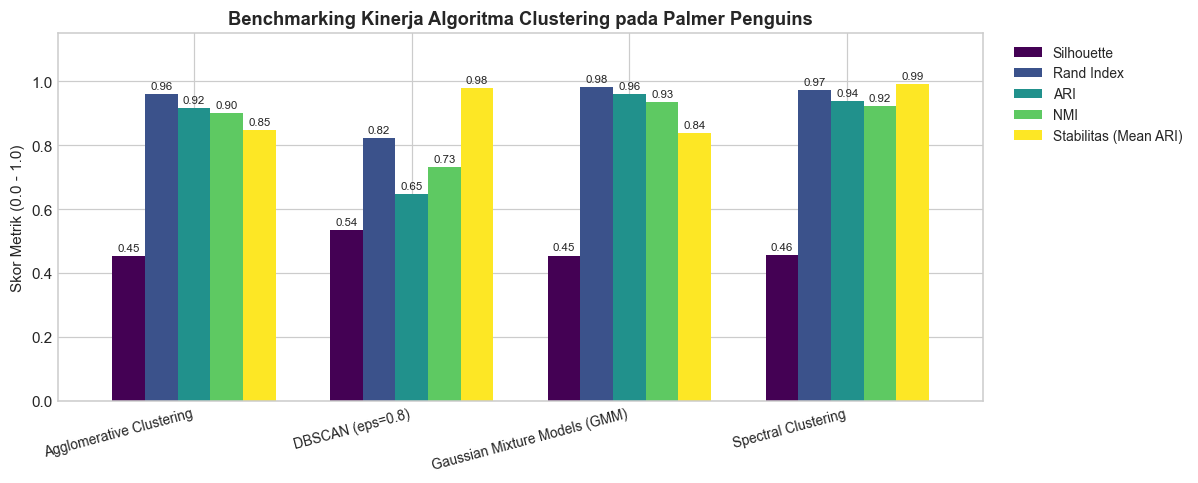

In [15]:
# Visualisasi Bar Chart Perbandingan Metrik
plot_cols = ['Silhouette', 'Rand Index', 'ARI', 'NMI', 'Stabilitas (Mean ARI)']
ax = summary_df.set_index('Algoritma')[plot_cols].plot(
    kind='bar', figsize=(11, 4.5), width=0.75, colormap='viridis'
)
plt.title("Benchmarking Kinerja Algoritma Clustering pada Palmer Penguins", fontsize=12, fontweight='bold')
plt.ylabel("Skor Metrik (0.0 - 1.0)", fontsize=10)
plt.xlabel("")
plt.xticks(rotation=15, ha='right', fontsize=9)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
plt.ylim(0, 1.15)

for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f"{h:.2f}", (p.get_x() + p.get_width() / 2., h),
                    ha='center', va='bottom', fontsize=7.5, xytext=(0, 2),
                    textcoords='offset points')

plt.tight_layout()
plt.show()

## 6. Kesimpulan & Rekomendasi Algoritma

### 1. Pemenang Mutlak: Gaussian Mixture Models (GMM)
- GMM mendominasi seluruh metrik eksternal secara mutlak: **ARI = 0.9603**, **NMI = 0.9349**, dan **Rand Index = 0.9817** (tingkat konkordansi >96% terhadap spesies asli).
- **Justifikasi Ilmiah:** Morfologi fisik organisme biologis secara alami mengikuti distribusi normal multivariat (*multivariate Gaussian distribution*). Parameter kovarians penuh (`covariance_type='full'`) memungkinkan GMM menangkap orientasi elipsoid dan kovarians antar fitur (misal: rasio panjang paruh terhadap sirip) yang unik pada masing-masing spesies, yang gagal ditangkap oleh pendekatan jarak Euclidean murni.

### 2. Analisis Kegagalan DBSCAN pada Pemisahan 3 Spesies
- DBSCAN mencatat skor Silhouette semu yang tinggi (0.5357) karena membuang titik batas terluar sebagai noise dan menggabungkan Adelie serta Chinstrap menjadi satu super-kluster padat berjarak jauh dari Gentoo (hanya 2 kluster terbentuk).
- Tidak adanya jurang kerapatan (*density gap*) antara Adelie dan Chinstrap dalam ruang Euclidean membuat DBSCAN tidak cocok untuk partisi taksonomi kontinu.

### 3. Alternatif Deterministik Terbaik: Spectral Clustering
- Menempati peringkat kedua evaluasi eksternal (ARI = 0.9378, NMI = 0.9208) dengan **tingkat kestabilan subsampel tertinggi mutlak (0.9912)** berkat kekokohan topologi graf *k*-NN Laplacian.